In [3]:
!md5sum cifar-10-python.tar.gz
!tar -xzf cifar-10-python.tar.gz
!ls cifar-10-batches-py

c58f30108f718f92721af3b95e74349a  cifar-10-python.tar.gz
batches.meta  data_batch_2  data_batch_4  readme.html
data_batch_1  data_batch_3  data_batch_5  test_batch


Читаем пять обучающих пакетов и тестовый из файлов, получаем массивы формы (N, 32, 32, 3). Выводим размеры, классы и примеры картинок для проверки.

Для обучения изображения нормализуем по каналам (вычитаем среднее, делим на разброс). Для обучающей выборки добавляем аугментацию (случайный сдвиг и отражение), чтобы сеть меньше переобучалась. Класс `CifarDataset` отдаёт пару «картинка, метка».

устройство: cuda
обучающая выборка: (50000, 32, 32, 3) (50000,)
тестовая выборка: (10000, 32, 32, 3) (10000,)
форма одного изображения: (32, 32, 3) метка: 6
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


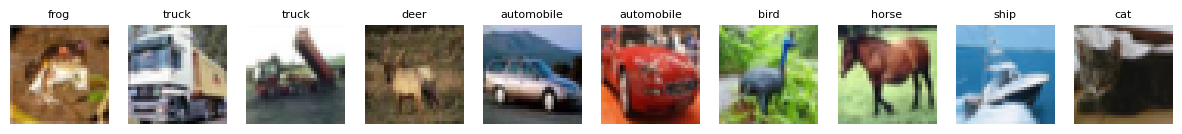

In [4]:
import time, pickle
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torchvision.transforms as T

torch.manual_seed(0)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("устройство:", device)

root = 'cifar-10-batches-py/'

def load_batch(name):
    with open(root + name, 'rb') as f:
        d = pickle.load(f, encoding='bytes')
    x = d[b'data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    return x, np.array(d[b'labels'])

parts = [load_batch(f'data_batch_{i}') for i in range(1, 6)]
x_train = np.concatenate([p[0] for p in parts])
y_train = np.concatenate([p[1] for p in parts])
x_test, y_test = load_batch('test_batch')
with open(root + 'batches.meta', 'rb') as f:
    classes = [c.decode() for c in pickle.load(f, encoding='bytes')[b'label_names']]

print("обучающая выборка:", x_train.shape, y_train.shape)
print("тестовая выборка:", x_test.shape, y_test.shape)
print("форма одного изображения:", x_train[0].shape, "метка:", y_train[0])
print(classes)

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i])
    ax.set_title(classes[y_train[i]], fontsize=8)
    ax.axis('off')
plt.show()

mean, std = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
train_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(),
                      T.ToTensor(), T.Normalize(mean, std)])
test_tf = T.Compose([T.ToTensor(), T.Normalize(mean, std)])

class CifarDataset(torch.utils.data.Dataset):
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.transform(Image.fromarray(self.images[i])), int(self.labels[i])

train_set = CifarDataset(x_train, y_train, train_tf)
test_set = CifarDataset(x_test, y_test, test_tf)

Сеть в духе VGG, описана собственным классом `Net` из базовых слоёв PyTorch:
- три блока из двух сверток 3×3 (64 -> 128 -> 256 каналов) с BatchNorm и ReLU, после каждого блока MaxPool 2×2 (размер 32 -> 16 -> 8 -> 4);
- классификатор: Flatten, Dropout, Linear 4096 -> 256, ReLU, Dropout, Linear 256 -> 10.

Функция потерь: кросс-энтропия. Оптимизатор: SGD с моментом и регуляризацией весов, скорость обучения меняется по расписанию OneCycleLR. Пакет 128, 30 эпох.

In [5]:
class Net(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False),
                                 nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
        self.features = nn.Sequential(
            block(3, 64), block(64, 64), nn.MaxPool2d(2),       # 32x32 -> 16x16
            block(64, 128), block(128, 128), nn.MaxPool2d(2),   # 16x16 -> 8x8
            block(128, 256), block(256, 256), nn.MaxPool2d(2),  # 8x8 -> 4x4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(256 * 4 * 4, 256),
            nn.ReLU(inplace=True), nn.Dropout(0.3), nn.Linear(256, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

batch_size, epochs = 128, 30
train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=2)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=512, shuffle=False, num_workers=2)

model = Net().to(device)
print("параметров:", sum(p.numel() for p in model.parameters()))

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=5e-4, nesterov=True)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=0.1, epochs=epochs,
                                                steps_per_epoch=len(train_loader))

параметров: 2197706


На каждом пакете: прямой проход, ошибка, обратное распространение, шаг оптимизатора. После каждой эпохи выводим ошибку, ошибку классификации и точность на обучающей выборке (по пакетам с аугментацией) и время эпохи. После обучения считаем ошибку классификации и точность на тестовой выборке, которую сеть в обучении не использовала.

In [6]:
def evaluate(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

history = {'train_loss': [], 'test_loss': []}
for epoch in range(epochs):
    model.train()
    t0 = time.time()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        scheduler.step()
        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    train_loss, train_acc = total_loss / n, correct / n
    test_loss, _ = evaluate(model, test_loader)
    history['train_loss'].append(train_loss)
    history['test_loss'].append(test_loss)
    print(f"эпоха {epoch+1:2d}: ошибка (loss) {train_loss:.4f}, "
          f"ошибка классификации {1 - train_acc:.2%}, точность {train_acc:.2%}, "
          f"время {time.time() - t0:.0f} c")

test_loss, test_acc = evaluate(model, test_loader)
print(f"на тесте: ошибка классификации {1 - test_acc:.2%}, точность {test_acc:.2%}")

эпоха  1: ошибка (loss) 1.3941, ошибка классификации 51.17%, точность 48.83%, время 24 c
эпоха  2: ошибка (loss) 0.9981, ошибка классификации 35.36%, точность 64.64%, время 21 c
эпоха  3: ошибка (loss) 0.9331, ошибка классификации 32.20%, точность 67.80%, время 22 c
эпоха  4: ошибка (loss) 0.8674, ошибка классификации 29.30%, точность 70.70%, время 22 c
эпоха  5: ошибка (loss) 0.7494, ошибка классификации 25.15%, точность 74.85%, время 21 c
эпоха  6: ошибка (loss) 0.6347, ошибка классификации 21.38%, точность 78.62%, время 22 c
эпоха  7: ошибка (loss) 0.5731, ошибка классификации 19.25%, точность 80.75%, время 22 c
эпоха  8: ошибка (loss) 0.5344, ошибка классификации 17.99%, точность 82.01%, время 21 c
эпоха  9: ошибка (loss) 0.5079, ошибка классификации 17.10%, точность 82.90%, время 22 c
эпоха 10: ошибка (loss) 0.4853, ошибка классификации 16.26%, точность 83.74%, время 22 c
эпоха 11: ошибка (loss) 0.4656, ошибка классификации 15.77%, точность 84.23%, время 21 c
эпоха 12: ошибка (los

Ошибка по эпохам на обучающей и тестовой выборках.

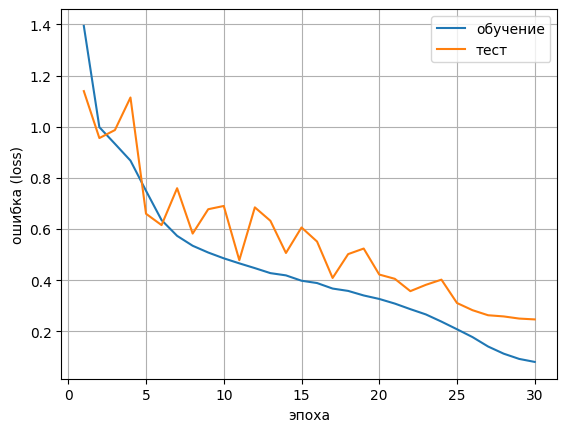

In [7]:
plt.plot(range(1, epochs + 1), history['train_loss'], label='обучение')
plt.plot(range(1, epochs + 1), history['test_loss'], label='тест')
plt.xlabel('эпоха'); plt.ylabel('ошибка (loss)'); plt.legend(); plt.grid(True)
plt.show()